# 50 Startups Data

### 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score

### 2. Load Dataset 

In [2]:
data = pd.read_csv('50_Startups.csv')
data.head()

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


### 3. Basic Statistic & EDA

In [3]:
data.describe()

,R&D Spend,Administration,Marketing Spend,Profit
count,50.000000,50.000000,50.000000,50.000000
mean,73721.615600,121344.639600,211025.097800,112012.639200
std,45902.256482,28017.802755,122290.310726,40306.180338
min,0.000000,51283.140000,0.000000,14681.400000
25%,39936.370000,103730.875000,129300.132500,90138.902500
50%,73051.080000,122699.795000,212716.240000,107978.190000
75%,101602.800000,144842.180000,299469.085000,139765.977500
max,165349.200000,182645.560000,471784.100000,192261.830000


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing Spend  50 non-null     float64
 3   State            50 non-null     str    
 4   Profit           50 non-null     float64
dtypes: float64(4), str(1)
memory usage: 2.5 KB


In [5]:
data.duplicated().sum()

np.int64(0)

In [6]:
data.shape

(50, 5)

### Distribution of Profit

<Axes: xlabel='Profit', ylabel='Count'>

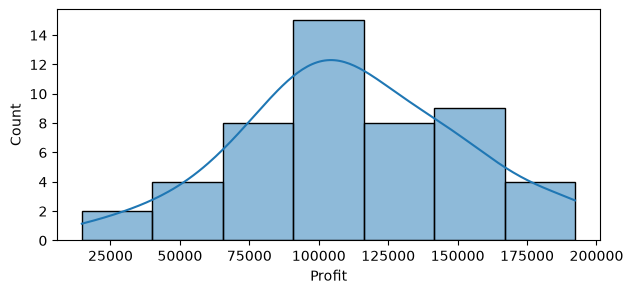

In [7]:
plt.figure(figsize=(7, 3))
sns.histplot(data['Profit'], kde=True)

### Profit by State

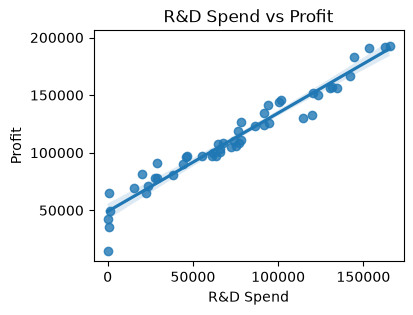

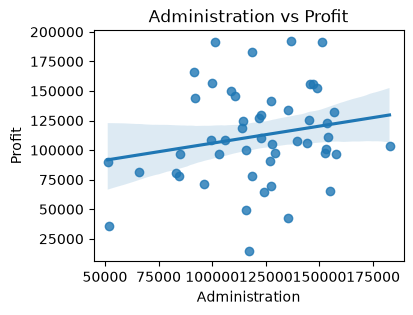

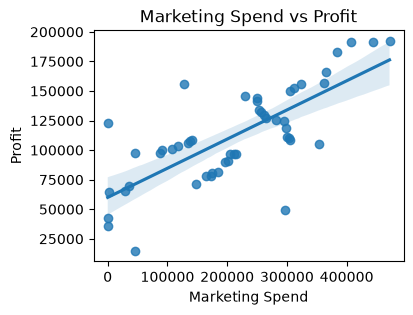

In [8]:
features = ['R&D Spend', 'Administration', 'Marketing Spend']

for feature in features:
    plt.figure(figsize=(4, 3))
    sns.regplot(data=data, x=feature, y='Profit')
    plt.title(f'{feature} vs Profit')

### Profit by State

<Axes: xlabel='State', ylabel='Profit'>

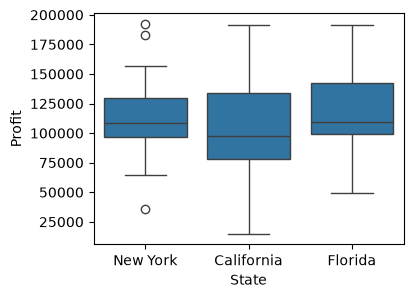

In [9]:
plt.figure(figsize=(4, 3))
sns.boxplot(data=data, x='State', y='Profit')

<Axes: >

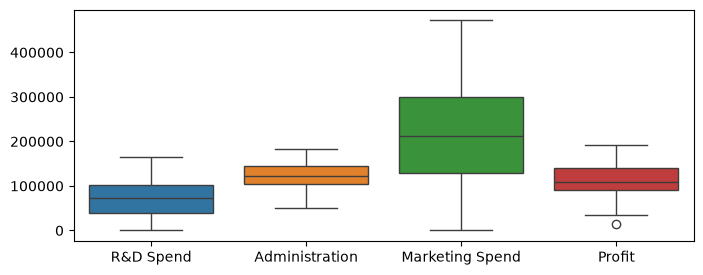

In [10]:
plt.figure(figsize=[8,3])
sns.boxplot(data)

<Axes: xlabel='Profit'>

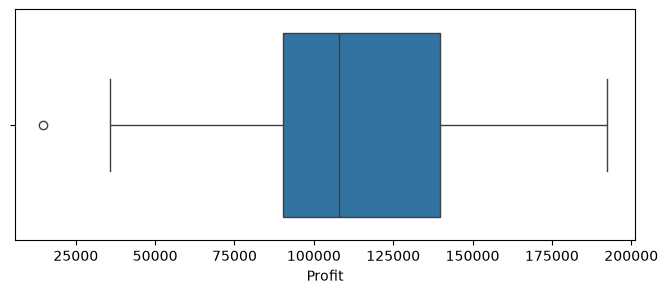

In [11]:
plt.figure(figsize=[8,3])
sns.boxplot(data, x='Profit')

### Pairplot

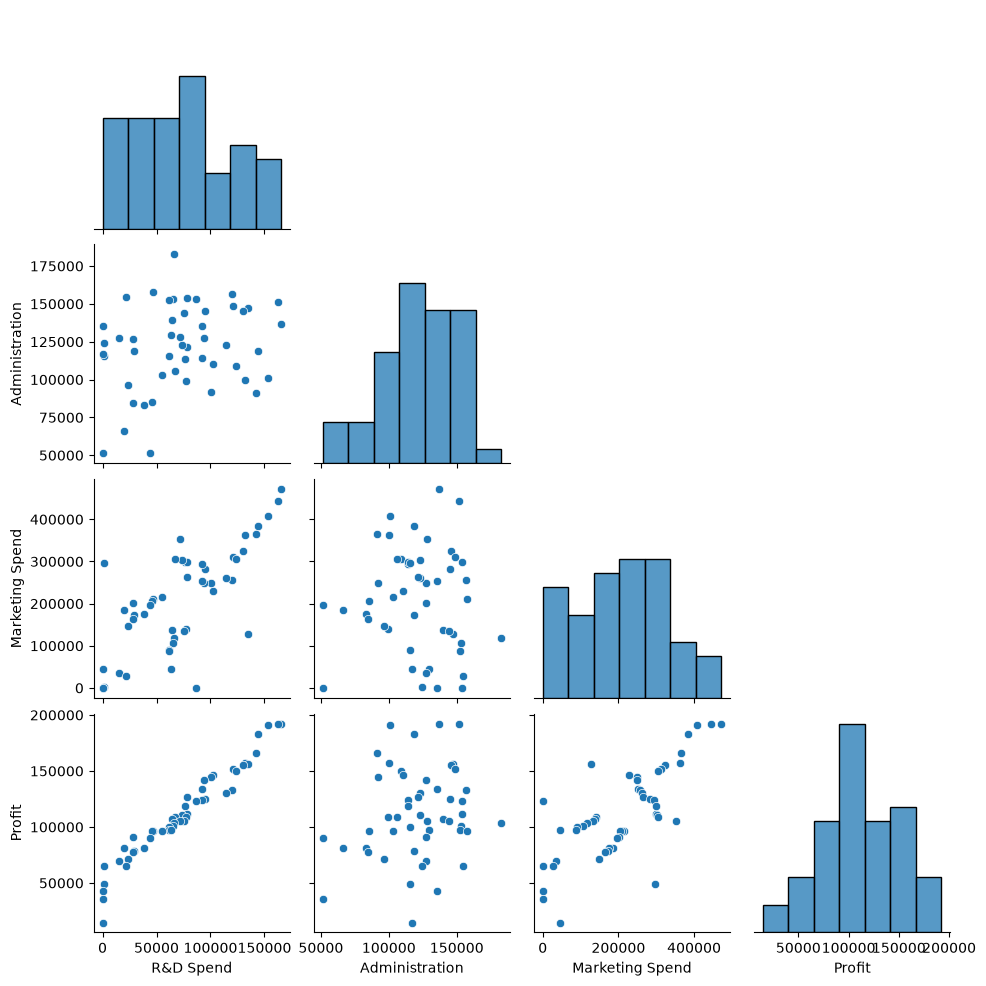

In [12]:
sns.pairplot(data, vars=['R&D Spend', 'Administration','Marketing Spend', 'Profit'], diag_kind='hist', corner=True)

### 4. Impute Outliers

In [13]:
# IQR method

q1 = data['Profit'].quantile(0.25)
q3 = data['Profit'].quantile(0.75)
Q2 = data['Profit'].quantile(0.50)
IQR = q3-q1

lower_bound = q1 - 1.5* IQR
upper_bound = q3 + 1.5* IQR

In [14]:
data['Profit'] = np.where(
    data['Profit']<lower_bound, lower_bound,
    np.where(
        data['Profit']>upper_bound, upper_bound, data['Profit']))

<Axes: xlabel='Profit'>

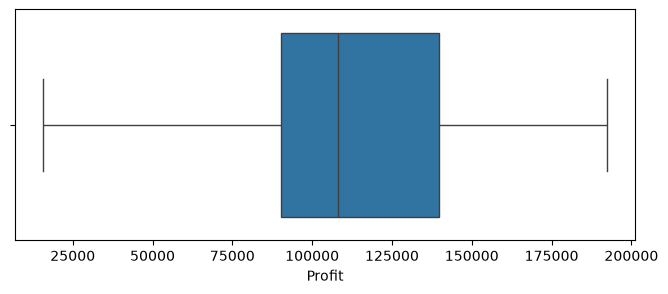

In [15]:
plt.figure(figsize=[8,3])
sns.boxplot(data, x='Profit')

### EDA

<Axes: xlabel='Marketing Spend', ylabel='Profit'>

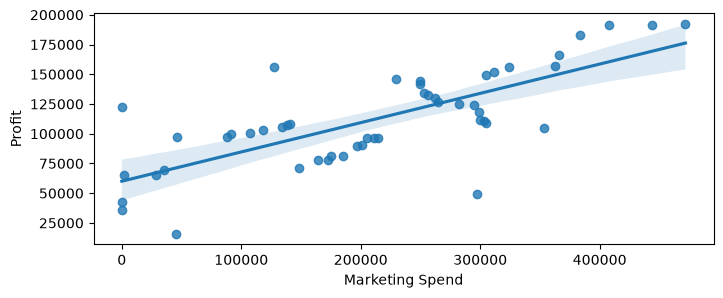

In [16]:
plt.figure(figsize=[8,3])
sns.regplot(data, x='Marketing Spend', y='Profit')

<Axes: >

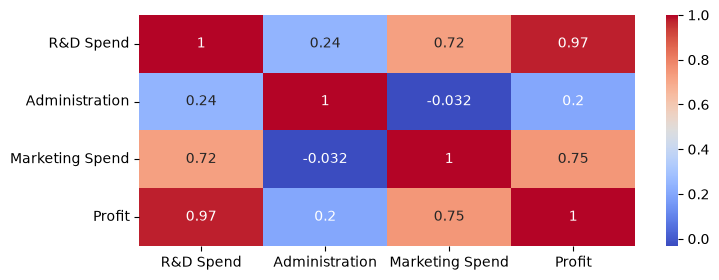

In [17]:
plt.figure(figsize=[8,3])
corr = data.select_dtypes(include='number').corr()

# corr = data.corr(numeric_only=True)

sns.heatmap(corr, annot=True, cmap='coolwarm')

###  5. Data Sapmling

In [18]:
X = data[['R&D Spend', 'Administration', 'Marketing Spend']]
y = data['Profit']

In [19]:
X__train, X_test, y__train, y_test = train_test_split(X, y , test_size=0.2, random_state=40)

In [20]:
X__train.head()

,R&D Spend,Administration,Marketing Spend
16,78013.11,121597.55,264346.06
35,46014.02,85047.44,205517.64
25,64664.71,139553.16,137962.62
21,78389.47,153773.43,299737.29
44,22177.74,154806.14,28334.72


In [21]:
y__train.head()

16    126992.93
35     96479.51
25    107404.34
21    111313.02
44     65200.33
Name: Profit, dtype: float64

## 6. train model

### KNN default neighbour model

In [22]:
knn = KNeighborsRegressor()    # by default 5 neighbours 
knn.fit(X__train, y__train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


#### evaluating model

In [23]:
pred_y = knn.predict(X_test)
accuracy = r2_score(y_test, pred_y)*100
print(accuracy)
error = 100-accuracy
print(error)
print(knn.get_params()['n_neighbors'])

79.27468583955743
20.725314160442565
5


#### KNN for all neighbour model

In [24]:
lst = []
rng = int(round(np.sqrt(data.shape[0]),0))
for i in range(1, rng):
    knn = KNeighborsRegressor(n_neighbors=i)
    knn.fit(X__train, y__train)
    pred_y = knn.predict(X_test)
    accuracy = r2_score(y_test, pred_y)*100
    error = 100-accuracy
    lst.append(error)
print(lst)

[12.377582364686887, 11.585531233115688, 8.782861174214275, 15.888771330924797, 20.725314160442565, 19.102309519846784]


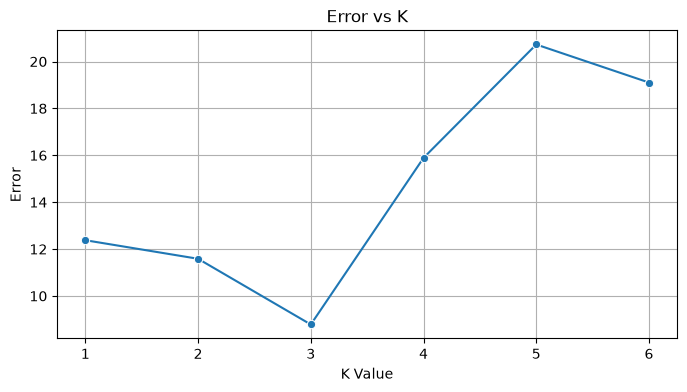

In [25]:
plt.figure(figsize=(8,4))
sns.lineplot(x= range(1,rng), y=lst, marker='o')
# plt.plot(range(1,rng), lst)
plt.xlabel("K Value")
plt.ylabel("Error")
plt.title("Error vs K")
plt.grid()
plt.show()

### multi linear regression

In [26]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X__train, y__train)
pred_y = model.predict(X_test)
r2_score(y_test, pred_y)*100

93.7853101235576

## 7. final model training 

In [27]:
knn = KNeighborsRegressor(n_neighbors=3)
knn.fit(X__train, y__train)
pred_y = knn.predict(X_test)
print("R2 Score :", r2_score(y_test, pred_y)*100)

R2 Score : 91.21713882578572


## 8. final evaluation 

In [28]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

print("MAE :", round(mean_absolute_error(y_test, pred_y),2))
print("MSE :", round(mean_squared_error(y_test, pred_y),2))
print("RMSE :", round(np.sqrt(mean_squared_error(y_test, pred_y)), 2))

MAE : 10808.33
MSE : 257120895.67
RMSE : 16034.99


In [29]:
result = pd.DataFrame({"Actual": y_test, "Predicted": pred_y})
result.head(10)

,Actual,Predicted
33,96778.92,89397.820000
29,101004.64,102166.493333
49,15698.29,59173.013333
38,81229.06,82917.910000
45,64926.08,59173.013333
0,192261.83,177228.390000
18,124266.90,112520.090000
4,166187.94,163217.690000
11,144259.40,139208.170000
2,191050.39,177228.390000


Text(0.5, 1.0, 'Actual vs Predicted Profit')

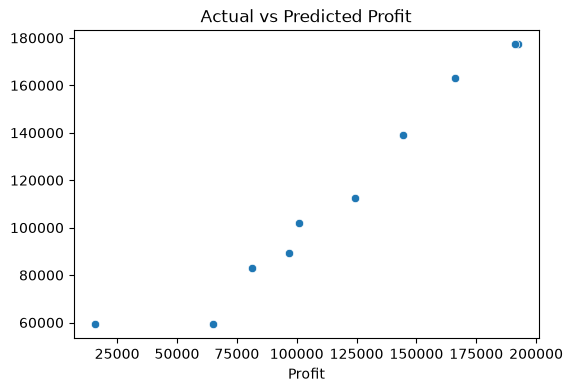

In [30]:
plt.figure(figsize=(6, 4))
sns.scatterplot(x=y_test, y=pred_y)
plt.title("Actual vs Predicted Profit")
